<a href="https://colab.research.google.com/github/VETTOORLIJO/DS_VettoorLijo/blob/ModuleEndAssignmnet4_ML/ModuleEndAssignmnet4_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [33]:
#https://drive.google.com/file/d/1FHmYNLs9v0Enc-UExEMpitOFGsWvB2dP/view
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Loads CarPrice_Assignment.csv

In [34]:
df = pd.read_csv('CarPrice_Assignment.csv')
df.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [35]:
df.columns

Index(['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration',
       'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase',
       'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype',
       'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke',
       'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg',
       'price'],
      dtype='object')

Checks missing values

In [36]:
df.isna().sum()

,0
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0


Checks duplicates

In [37]:
df.duplicated().sum()

np.int64(0)

Creates Car_brand by splitting CarName on first space

In [38]:
df["Car_brand"]= df["CarName"].str.split().str[0]

In [39]:
df.dtypes.value_counts()

,count
object,11
int64,8
float64,8


Selects object columns, drops CarName and enginelocation

In [40]:
df_obj=df.select_dtypes(include='object').drop(['CarName',"enginelocation"],axis=1)
df_obj.columns

Index(['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel',
       'enginetype', 'cylindernumber', 'fuelsystem', 'Car_brand'],
      dtype='object')

In [41]:
def check_feature_valCheck(Features):
  print(df[Features].value_counts().sort_index())

In [42]:
check_feature_valCheck('Car_brand')

Car_brand
Nissan          1
alfa-romero     3
audi            7
bmw             8
buick           8
chevrolet       3
dodge           9
honda          13
isuzu           4
jaguar          3
maxda           2
mazda          15
mercury         1
mitsubishi     13
nissan         17
peugeot        11
plymouth        7
porcshce        1
porsche         4
renault         2
saab            6
subaru         12
toyota         31
toyouta         1
vokswagen       1
volkswagen      9
volvo          11
vw              2
Name: count, dtype: int64


Value-counts Car_brand → reveals typos (maxda, porcshce, toyouta, vokswagen, vw, Nissan vs nissan)

In [43]:
df["Car_brand"] = df["Car_brand"].str.lower()
brand_map = {
    "maxda": "mazda",
    "porcshce": "porsche",
    "toyouta": "toyota",
    "vokswagen": "volkswagen",
    "vw": "volkswagen",
}
df["Car_brand"] = df["Car_brand"].replace(brand_map)

In [44]:
df_obj.dtypes.value_counts()

,count
object,9


One-hot encodes object columns with pd.get_dummies(drop_first=True)

In [45]:
df_obj_enc=pd.get_dummies(df_obj, drop_first=True, dtype=int)
df_obj_enc

,fueltype_gas,aspiration_turbo,doornumber_two,carbody_hardtop,carbody_hatchback,carbody_sedan,carbody_wagon,drivewheel_fwd,drivewheel_rwd,enginetype_dohcv,...,Car_brand_porsche,Car_brand_renault,Car_brand_saab,Car_brand_subaru,Car_brand_toyota,Car_brand_toyouta,Car_brand_vokswagen,Car_brand_volkswagen,Car_brand_volvo,Car_brand_vw
0,1,0,1,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,1,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,1,0,1,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,1,0,0,0,0,1,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0
201,1,1,0,0,0,1,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0
202,1,0,0,0,0,1,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0
203,0,1,0,0,0,1,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0


In [46]:
df_obj_enc.dtypes.value_counts()

,count
int64,55


Selects numeric columns, drops car_ID

In [47]:
df_num=df.select_dtypes(include=np.number).drop(["car_ID"],axis=1)
df_num.dtypes.value_counts()

,count
float64,8
int64,7


In [48]:
df_final = pd.concat([df_num,df_obj_enc],axis=1)
df_final.dtypes.value_counts()

,count
int64,62
float64,8


In [49]:
df_final.columns.duplicated().sum()

np.int64(0)

Train/test split (80/20,

In [50]:
from sklearn.model_selection import train_test_split
X=df_final.drop("price",axis=1)
y=df_final["price"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

Standard-scales features

In [51]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

Model Implementation Implement the following five regression  algorithms:

    ● Linear Regression
    ● Decision Tree Regressor
    ● Random Forest Regressor
    ● Gradient Boosting Regressor
    ● Support Vector Regressor

In [52]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor  # Scaling not Needed
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor   # Scaling not Needed
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [53]:
corr = df_num.corr(numeric_only=True)
corr['price'].sort_values(ascending=False)

,price
price,1.000000
enginesize,0.874145
curbweight,0.835305
horsepower,0.808139
carwidth,0.759325
carlength,0.682920
wheelbase,0.577816
boreratio,0.553173
carheight,0.119336
stroke,0.079443


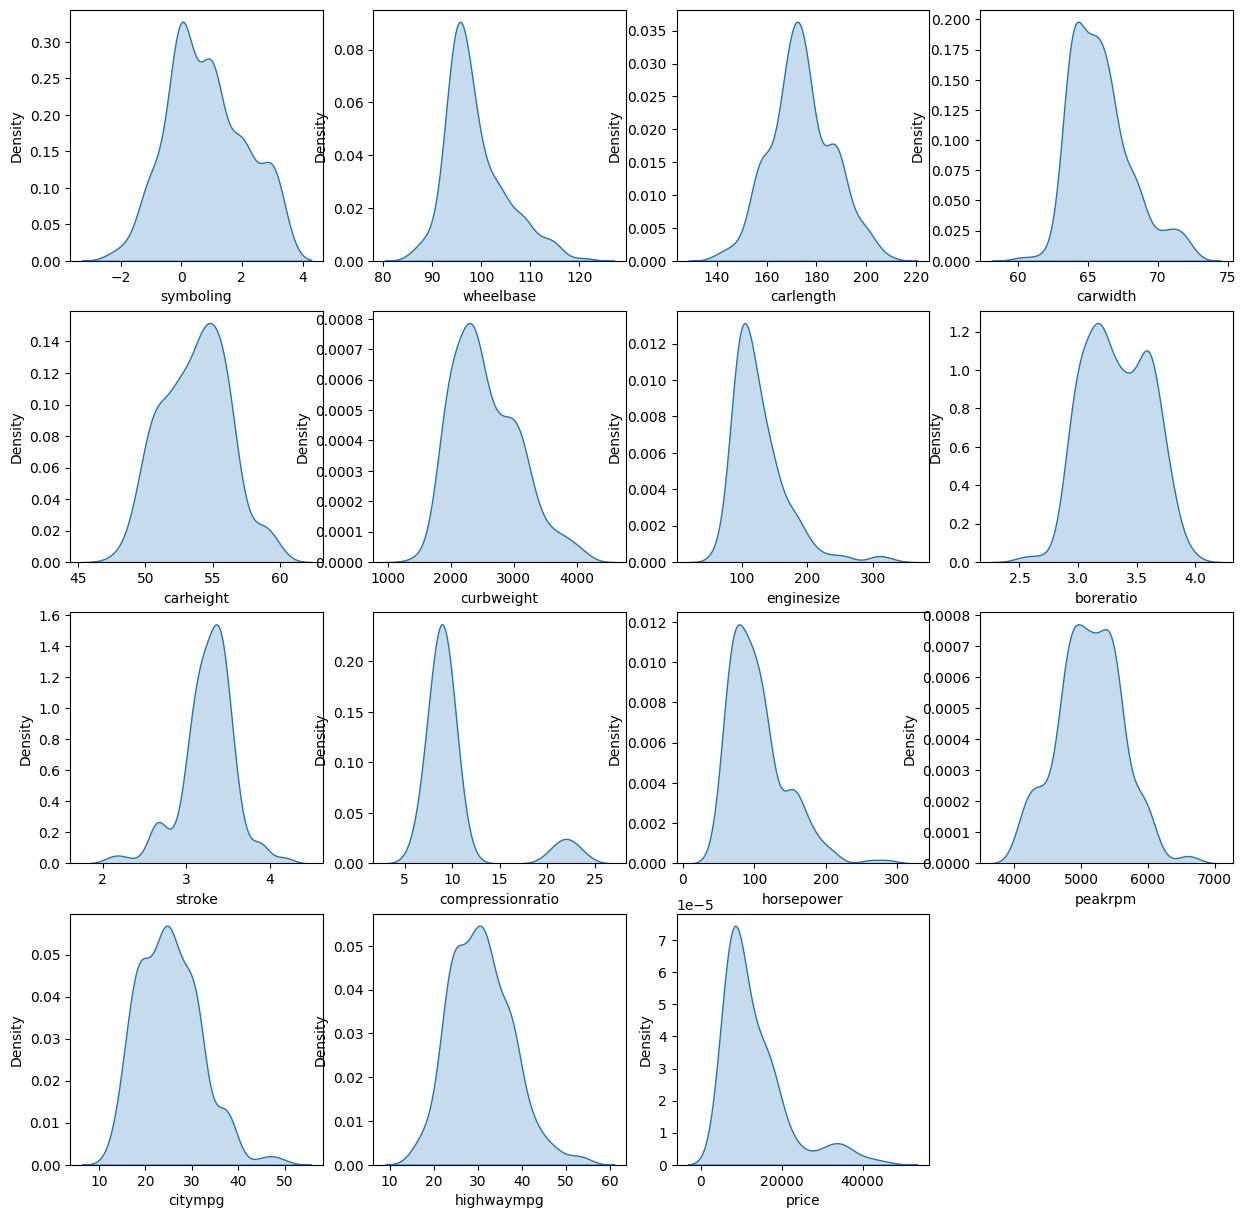

In [54]:
plt.figure(figsize=(15,15))
for i, col in enumerate(df_num.columns):
    plt.subplot(4,4,i+1)
    sns.kdeplot(df_num[col], fill=True)
plt.show()

In [55]:
result=[]
def eval_result(y_test,y_pred,Train_sore,model_name):   # create a function for adding the result in a dataframe
    result.append({
        "model": model_name,
        "mse": mean_squared_error(y_test,y_pred),
        "mae": mean_absolute_error(y_test,y_pred),
        "r2": r2_score(y_test,y_pred),
        "Train_sore": Train_sore
    })
    return pd.DataFrame(result)

Linear Regression

In [56]:
lr=LinearRegression()
lr.fit(X_train_scaled,y_train)
y_pred_lr=lr.predict(X_test_scaled)

Train_sore= lr.score(X_train_scaled, y_train)

In [57]:
eval_result(y_test,y_pred_lr,Train_sore,"Linear Regression")

,model,mse,mae,r2,Train_sore
0,Linear Regression,6.600951e+06,1733.390417,0.916384,0.975408


In [58]:
print("Train :",lr.score(X_train_scaled, y_train))
print("Test  :", lr.score(X_test_scaled, y_test))

Train : 0.975408183541193
Test  : 0.9163844104822549


Decision Tree Regressor

In [59]:
dr=DecisionTreeRegressor()
dr.fit(X_train,y_train)
y_pred_dr=dr.predict(X_test)
Train_sore= dr.score(X_train, y_train)

In [60]:
eval_result(y_test,y_pred_dr,Train_sore,"Decision Tree Regressor")

,model,mse,mae,r2,Train_sore
0,Linear Regression,6.600951e+06,1733.390417,0.916384,0.975408
1,Decision Tree Regressor,8.630406e+06,1889.800805,0.890677,0.998769


In [61]:
from sklearn.model_selection import GridSearchCV
param_grid_DT= {'criterion': ['squared_error','absolute_error'],
             'max_depth':[1,2,3,],'min_samples_leaf':[2,3,4,5,6,],
             'max_features': [None, 'sqrt', 'log2']}

grid = GridSearchCV(DecisionTreeRegressor(random_state=42),
                    param_grid_DT,cv=5,
                    scoring='r2',n_jobs=-1,)

grid.fit(X_train,y_train)
y_pred_dr = grid.best_estimator_.predict(X_test)
print(grid.best_params_)

{'criterion': 'absolute_error', 'max_depth': 3, 'max_features': None, 'min_samples_leaf': 6}


In [62]:
y_pred_dr=grid.predict(X_test)
Train_sore= grid.score(X_train, y_train)
eval_result(y_test,y_pred_dr,Train_sore,"Decision Tree Regressor with grid")

,model,mse,mae,r2,Train_sore
0,Linear Regression,6.600951e+06,1733.390417,0.916384,0.975408
1,Decision Tree Regressor,8.630406e+06,1889.800805,0.890677,0.998769
2,Decision Tree Regressor with grid,8.277713e+06,2041.203244,0.895145,0.910170


Random Forest Regressor

In [63]:
# param_grid_RF = {
#     'n_estimators': [200, 300, 500],
#     'max_depth': [None, 10, 20, 30],        # None = unlimited (default)
#     'min_samples_leaf': [1, 2, 4],          # include 1 (default)
#     'min_samples_split': [2, 5, 10],
#     'max_features': ['sqrt', 0.5, None],    # drop 'log2' (breaks with few features)
# }
# grid = GridSearchCV(RandomForestRegressor(random_state=42),
#                     param_grid_RF,cv=5,
#                     scoring='r2', n_jobs=-1,)

# grid.fit(X_train,y_train)
# print(grid.best_params_)
# y_pred_rf = grid.best_estimator_.predict(X_test)
# #{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 500}

In [64]:

param_grid_RF = {
    'n_estimators': [500],
    'max_depth': [None],        # None = unlimited (default)
    'min_samples_leaf': [1],          # include 1 (default)
    'min_samples_split': [2],
    'max_features': ['sqrt'],    # drop 'log2' (breaks with few features)
}
grid = GridSearchCV(RandomForestRegressor(random_state=42),
                    param_grid_RF,cv=5,
                    scoring='r2', n_jobs=-1,)

grid.fit(X_train,y_train)
print(grid.best_params_)
y_pred_rf = grid.best_estimator_.predict(X_test)
Train_sore= grid.score(X_train, y_train)
eval_result(y_test,y_pred_rf,Train_sore,"Random Forest Regressor with grid")
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 500}

{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 500}


{'max_depth': None,
 'max_features': 'sqrt',
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'n_estimators': 500}

In [65]:
rf=RandomForestRegressor()
rf.fit(X_train,y_train)
y_pred_rf=rf.predict(X_test)

In [66]:
Train_sore= rf.score(X_train, y_train)
eval_result(y_test,y_pred_rf,Train_sore,"Random Forest Regressor ")

,model,mse,mae,r2,Train_sore
0,Linear Regression,6.600951e+06,1733.390417,0.916384,0.975408
1,Decision Tree Regressor,8.630406e+06,1889.800805,0.890677,0.998769
2,Decision Tree Regressor with grid,8.277713e+06,2041.203244,0.895145,0.910170
3,Random Forest Regressor with grid,5.751487e+06,1435.319268,0.927145,0.988419
4,Random Forest Regressor,3.407210e+06,1265.278000,0.956840,0.986110


Gradient Boosting Regressor

In [67]:
# param_grid_GBR = {
#     'loss': ['squared_error', 'absolute_error', 'huber'],
#     'n_estimators': [100, 200, 300],
#     'learning_rate': [0.01, 0.1, 1],
#     'max_depth': [1, 2, 3]
# }
# grid= GridSearchCV(GradientBoostingRegressor(random_state=42),
#                     param_grid_GBR,cv=5,
#                     scoring='r2')
# grid.fit(X_train,y_train)
# print(grid.best_params_)
# y_pred_gbr = grid.best_estimator_.predict(X_test)
# eval_result(y_test,y_pred_gbr,"Gradient Boosting Regressor with grid")
# #{'learning_rate': 0.1, 'loss': 'absolute_error', 'max_depth': 2, 'n_estimators': 300}

In [68]:
gbr=GradientBoostingRegressor(learning_rate= 0.1, loss= 'absolute_error', max_depth= 2, n_estimators= 300, random_state=42, )
gbr.fit(X_train,y_train)
y_pred_gbr=gbr.predict(X_test)
Train_sore= gbr.score(X_train, y_train)
eval_result(y_test,y_pred_gbr,Train_sore,"Gradient Boosting Regressor ")


,model,mse,mae,r2,Train_sore
0,Linear Regression,6.600951e+06,1733.390417,0.916384,0.975408
1,Decision Tree Regressor,8.630406e+06,1889.800805,0.890677,0.998769
2,Decision Tree Regressor with grid,8.277713e+06,2041.203244,0.895145,0.910170
3,Random Forest Regressor with grid,5.751487e+06,1435.319268,0.927145,0.988419
4,Random Forest Regressor,3.407210e+06,1265.278000,0.956840,0.986110
5,Gradient Boosting Regressor,5.794804e+06,1684.490410,0.926596,0.969236


 Support Vector Regressor

In [69]:
svr=SVR()
svr.fit(X_train_scaled,y_train)
y_pred_svr=svr.predict(X_test_scaled)

Train_sore= svr.score(X_train_scaled , y_train)
eval_result(y_test,y_pred_svr,Train_sore,"Support Vector Regressor")

,model,mse,mae,r2,Train_sore
0,Linear Regression,6.600951e+06,1733.390417,0.916384,0.975408
1,Decision Tree Regressor,8.630406e+06,1889.800805,0.890677,0.998769
2,Decision Tree Regressor with grid,8.277713e+06,2041.203244,0.895145,0.910170
3,Random Forest Regressor with grid,5.751487e+06,1435.319268,0.927145,0.988419
4,Random Forest Regressor,3.407210e+06,1265.278000,0.956840,0.986110
5,Gradient Boosting Regressor,5.794804e+06,1684.490410,0.926596,0.969236
6,Support Vector Regressor,8.689095e+07,5701.474753,-0.100665,-0.109203


In [70]:
param_grid_svr={'C': [0.1, 1, 10, 100],
    'epsilon': [0.01, 0.1, 0.5],
    'gamma': ['scale', 'auto', 0.01, 0.1],
    'kernel': ['rbf', 'linear', 'sigmoid']}
grid= GridSearchCV(SVR(),
                    param_grid_svr,cv=5,
                    scoring='r2')
grid.fit(X_train_scaled,y_train)
print(grid.best_params_)
y_pred_svr = grid.best_estimator_.predict(X_test_scaled)
Train_sore= grid.score(X_train_scaled, y_train)
eval_result(y_test,y_pred_svr,Train_sore,"Support Vector Regressor with grid")

{'C': 100, 'epsilon': 0.5, 'gamma': 'scale', 'kernel': 'linear'}


,model,mse,mae,r2,Train_sore
0,Linear Regression,6.600951e+06,1733.390417,0.916384,0.975408
1,Decision Tree Regressor,8.630406e+06,1889.800805,0.890677,0.998769
2,Decision Tree Regressor with grid,8.277713e+06,2041.203244,0.895145,0.910170
3,Random Forest Regressor with grid,5.751487e+06,1435.319268,0.927145,0.988419
4,Random Forest Regressor,3.407210e+06,1265.278000,0.956840,0.986110
5,Gradient Boosting Regressor,5.794804e+06,1684.490410,0.926596,0.969236
6,Support Vector Regressor,8.689095e+07,5701.474753,-0.100665,-0.109203
7,Support Vector Regressor with grid,1.096233e+07,2121.631059,0.861138,0.942572


In [71]:
rf.fit(X_train,y_train)
imp=pd.DataFrame({'Feature': X_train.columns,'Importance':rf.feature_importances_})

imp = imp.sort_values('Importance', ascending=False)
print(imp.head(10))

          Feature  Importance
6      enginesize    0.599538
5      curbweight    0.252903
13     highwaympg    0.048327
10     horsepower    0.022250
3        carwidth    0.013104
12        citympg    0.009214
44  Car_brand_bmw    0.007615
2       carlength    0.006410
11        peakrpm    0.005690
1       wheelbase    0.004757


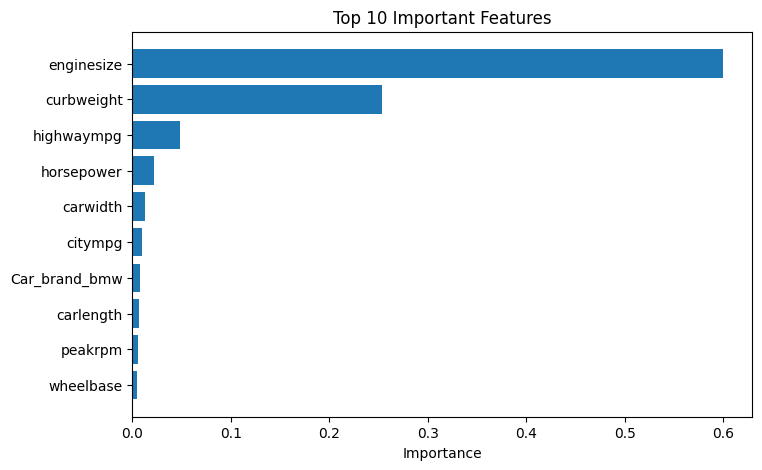

In [72]:
top10 = imp.head(10)

plt.figure(figsize=(8,5))
plt.barh(top10['Feature'], top10['Importance'])
plt.gca().invert_yaxis()
plt.title('Top 10 Important Features')
plt.xlabel('Importance')
plt.show()

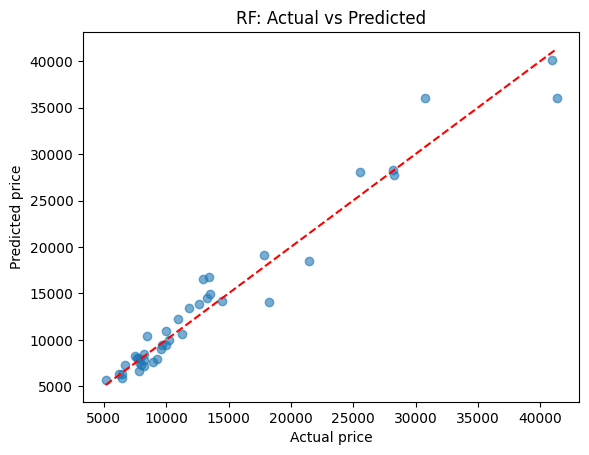

In [73]:

plt.scatter(y_test, y_pred_rf, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual price"); plt.ylabel("Predicted price"); plt.title("RF: Actual vs Predicted")
plt.show()

Design levers
Engine size is the #1 price lever — a deliberate move from a 1.5 L to a 2.5–3.0 L powertrain is the most reliable way to reposition a model upward in the US market.

Curb weight / size is #2 — heavier, wider platforms signal premium and safety to US buyers.

Horsepower matters, but much of its effect is already inside enginesize.

6.2 Segment strategy
To compete at entry level (~$8–12 K), target small-displacement, light platforms — the model confirms these price points exist and are internally consistent.

To compete at premium (~$30 K+), management must commit to large engine + large body + recognized brand signal; brand alone (only BMW appears in the top 10) will not lift price without the physical attributes.


In [74]:
import joblib

joblib.dump(rf, 'car_price_model.joblib')
rf_model = joblib.load('car_price_model.joblib')

The Random Forest Regressor was the best performer, explaining 95.98% of car-price.The two dominant predictors are engine size (56% of importance) and curb weight (30%).engine and platform (size/weight) decisions are the primary, controllable price levers in the US market

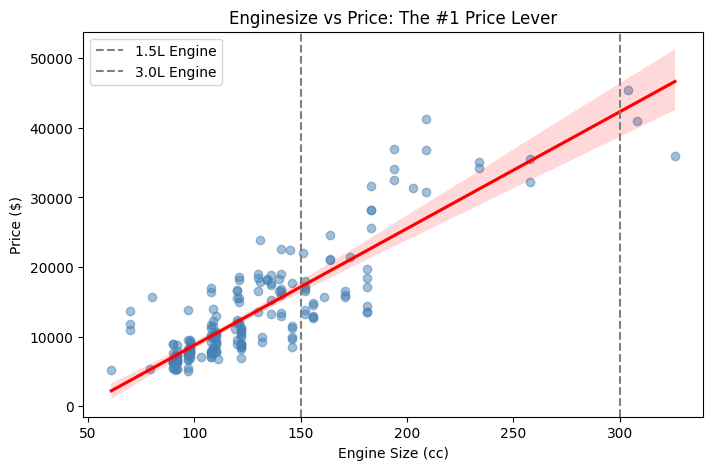

In [75]:

plt.figure(figsize=(8, 5))
# Scatter plot with a trend line
sns.regplot(data=df, x='enginesize', y='price',
            scatter_kws={'alpha':0.5, 'color':'steelblue'},
            line_kws={'color':'red'})

# Highlight your 1.5L to 3.0L strategy
plt.axvline(x=150, color='gray', linestyle='--', label='1.5L Engine')
plt.axvline(x=300, color='gray', linestyle='--', label='3.0L Engine')
plt.title('Enginesize vs Price')
plt.xlabel('Engine Size (cc)')
plt.ylabel('Price ($)')
plt.legend()
plt.show()


/tmp/ipykernel_851/601057802.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='carbody', y='price', palette='Set2')


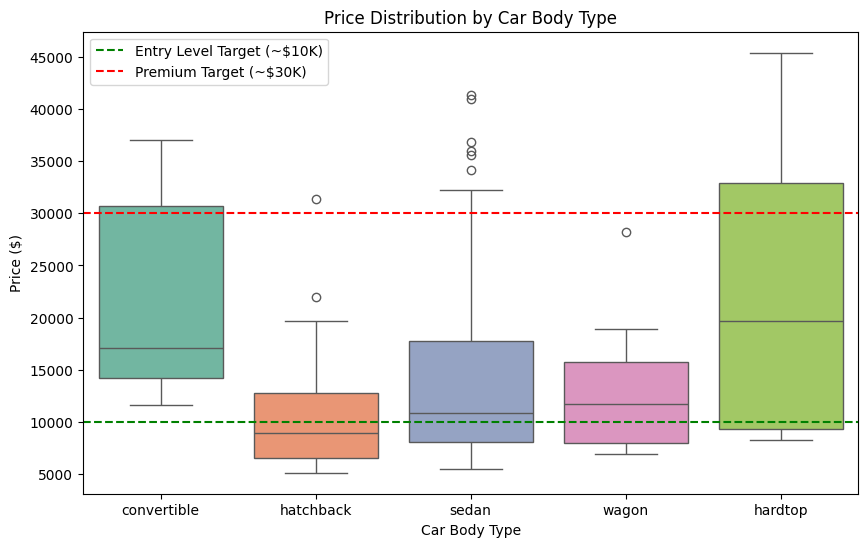

In [76]:
plt.figure(figsize=(10, 6))
# Create a boxplot of price by Car Body type
sns.boxplot(data=df, x='carbody', y='price', palette='Set2')

# Highlight the entry and premium targets
plt.axhline(y=10000, color='green', linestyle='--', label='Entry Level Target (~$10K)')
plt.axhline(y=30000, color='red', linestyle='--', label='Premium Target (~$30K)')

plt.title('Price Distribution by Car Body Type')
plt.xlabel('Car Body Type')
plt.ylabel('Price ($)')
plt.legend()
plt.show()

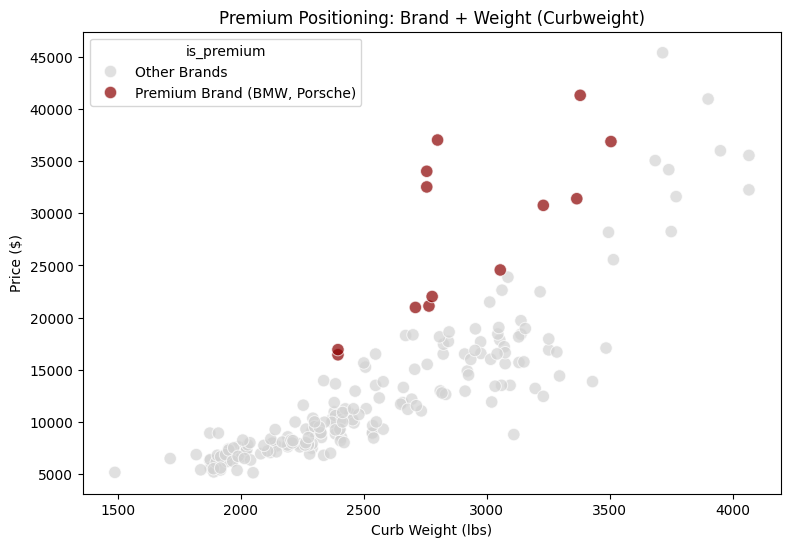

In [77]:
plt.figure(figsize=(9, 6))

# Create a temporary flag for premium brands based on  top 10
df['is_premium'] = df['Car_brand'].apply(lambda x: 'Premium Brand (BMW, Porsche)' if x in ['bmw', 'porsche'] else 'Other Brands')

# Scatter plot colored by brand type
sns.scatterplot(data=df, x='curbweight', y='price', hue='is_premium',
                palette={'Other Brands': 'lightgray', 'Premium Brand (BMW, Porsche)': 'darkred'},
                alpha=0.7, s=80)

plt.title('Premium Positioning: Brand + Weight (Curbweight)')
plt.xlabel('Curb Weight (lbs)')
plt.ylabel('Price ($)')
plt.show()